In [1]:
import torch
import torch.nn.functional as F
import math
import random
import torch.nn as nn
import numpy as np
def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)


class KANLinear(torch.nn.Module):
    def __init__(
        self,
        in_features,
        out_features,
        grid_size=5,
        spline_order=3,
        scale_noise=0.1,
        scale_base=1.0,
        scale_spline=1.0,
        enable_standalone_scale_spline=True,
        base_activation=torch.nn.SiLU,
        grid_eps=0.02,
        grid_range=[-1, 1],
        random_state=None
    ):
        super(KANLinear, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.grid_size = grid_size
        self.spline_order = spline_order

        if random_state is not None:
            torch.manual_seed(random_state)

        h = (grid_range[1] - grid_range[0]) / grid_size
        grid = (
            (
                torch.arange(-spline_order, grid_size + spline_order + 1) * h
                + grid_range[0]
            )
            .expand(in_features, -1)
            .contiguous()
        )
        self.register_buffer("grid", grid)

        self.base_weight = torch.nn.Parameter(torch.Tensor(out_features, in_features))
        self.spline_weight = torch.nn.Parameter(
            torch.Tensor(out_features, in_features, grid_size + spline_order)
        )
        if enable_standalone_scale_spline:
            self.spline_scaler = torch.nn.Parameter(
                torch.Tensor(out_features, in_features)
            )

        self.scale_noise = scale_noise
        self.scale_base = scale_base
        self.scale_spline = scale_spline
        self.enable_standalone_scale_spline = enable_standalone_scale_spline
        self.base_activation = base_activation()
        self.grid_eps = grid_eps

        self.reset_parameters()

    def reset_parameters(self):
        torch.nn.init.kaiming_uniform_(self.base_weight, a=math.sqrt(5) * self.scale_base)
        with torch.no_grad():
            noise = (
                (
                    torch.rand(self.grid_size + 1, self.in_features, self.out_features)
                    - 1 / 2
                )
                * self.scale_noise
                / self.grid_size
            )
            self.spline_weight.data.copy_(
                (self.scale_spline if not self.enable_standalone_scale_spline else 1.0)
                * self.curve2coeff(
                    self.grid.T[self.spline_order : -self.spline_order],
                    noise,
                )
            )
            if self.enable_standalone_scale_spline:
                torch.nn.init.kaiming_uniform_(self.spline_scaler, a=math.sqrt(5) * self.scale_spline)

    def b_splines(self, x: torch.Tensor):
        """
        Compute the B-spline bases for the given input tensor.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_features).

        Returns:
            torch.Tensor: B-spline bases tensor of shape (batch_size, in_features, grid_size + spline_order).
        """
        assert x.dim() == 2 and x.size(1) == self.in_features

        grid: torch.Tensor = (
            self.grid
        )  # (in_features, grid_size + 2 * spline_order + 1)
        x = x.unsqueeze(-1)
        bases = ((x >= grid[:, :-1]) & (x < grid[:, 1:])).to(x.dtype)
        for k in range(1, self.spline_order + 1):
            bases = (
                (x - grid[:, : -(k + 1)])
                / (grid[:, k:-1] - grid[:, : -(k + 1)])
                * bases[:, :, :-1]
            ) + (
                (grid[:, k + 1 :] - x)
                / (grid[:, k + 1 :] - grid[:, 1:(-k)])
                * bases[:, :, 1:]
            )

        assert bases.size() == (
            x.size(0),
            self.in_features,
            self.grid_size + self.spline_order,
        )
        return bases.contiguous()

    def curve2coeff(self, x: torch.Tensor, y: torch.Tensor):
        """
        Compute the coefficients of the curve that interpolates the given points.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_features).
            y (torch.Tensor): Output tensor of shape (batch_size, in_features, out_features).

        Returns:
            torch.Tensor: Coefficients tensor of shape (out_features, in_features, grid_size + spline_order).
        """
        assert x.dim() == 2 and x.size(1) == self.in_features
        assert y.size() == (x.size(0), self.in_features, self.out_features)

        A = self.b_splines(x).transpose(
            0, 1
        )  # (in_features, batch_size, grid_size + spline_order)
        B = y.transpose(0, 1)  # (in_features, batch_size, out_features)
        solution = torch.linalg.lstsq(
            A, B
        ).solution  # (in_features, grid_size + spline_order, out_features)
        result = solution.permute(
            2, 0, 1
        )  # (out_features, in_features, grid_size + spline_order)

        assert result.size() == (
            self.out_features,
            self.in_features,
            self.grid_size + self.spline_order,
        )
        return result.contiguous()

    @property
    def scaled_spline_weight(self):
        return self.spline_weight * (
            self.spline_scaler.unsqueeze(-1)
            if self.enable_standalone_scale_spline
            else 1.0
        )

    def forward(self, x: torch.Tensor):
        assert x.size(-1) == self.in_features
        original_shape = x.shape
        x = x.reshape(-1, self.in_features)

        base_output = F.linear(self.base_activation(x), self.base_weight)
        spline_output = F.linear(
            self.b_splines(x).view(x.size(0), -1),
            self.scaled_spline_weight.view(self.out_features, -1),
        )
        output = base_output + spline_output
        
        output = output.reshape(*original_shape[:-1], self.out_features)
        return output

    @torch.no_grad()
    def update_grid(self, x: torch.Tensor, margin=0.01):
        assert x.dim() == 2 and x.size(1) == self.in_features
        batch = x.size(0)

        splines = self.b_splines(x)  # (batch, in, coeff)
        splines = splines.permute(1, 0, 2)  # (in, batch, coeff)
        orig_coeff = self.scaled_spline_weight  # (out, in, coeff)
        orig_coeff = orig_coeff.permute(1, 2, 0)  # (in, coeff, out)
        unreduced_spline_output = torch.bmm(splines, orig_coeff)  # (in, batch, out)
        unreduced_spline_output = unreduced_spline_output.permute(
            1, 0, 2
        )  # (batch, in, out)

        # sort each channel individually to collect data distribution
        x_sorted = torch.sort(x, dim=0)[0]
        grid_adaptive = x_sorted[
            torch.linspace(
                0, batch - 1, self.grid_size + 1, dtype=torch.int64, device=x.device
            )
        ]

        uniform_step = (x_sorted[-1] - x_sorted[0] + 2 * margin) / self.grid_size
        grid_uniform = (
            torch.arange(
                self.grid_size + 1, dtype=torch.float32, device=x.device
            ).unsqueeze(1)
            * uniform_step
            + x_sorted[0]
            - margin
        )

        grid = self.grid_eps * grid_uniform + (1 - self.grid_eps) * grid_adaptive
        grid = torch.concatenate(
            [
                grid[:1]
                - uniform_step
                * torch.arange(self.spline_order, 0, -1, device=x.device).unsqueeze(1),
                grid,
                grid[-1:]
                + uniform_step
                * torch.arange(1, self.spline_order + 1, device=x.device).unsqueeze(1),
            ],
            dim=0,
        )

        self.grid.copy_(grid.T)
        self.spline_weight.data.copy_(self.curve2coeff(x, unreduced_spline_output))

    def regularization_loss(self, regularize_activation=1.0, regularize_entropy=1.0):
        """
        Compute the regularization loss.

        This is a dumb simulation of the original L1 regularization as stated in the
        paper, since the original one requires computing absolutes and entropy from the
        expanded (batch, in_features, out_features) intermediate tensor, which is hidden
        behind the F.linear function if we want an memory efficient implementation.

        The L1 regularization is now computed as mean absolute value of the spline
        weights. The authors implementation also includes this term in addition to the
        sample-based regularization.
        """
        l1_fake = self.spline_weight.abs().mean(-1)
        regularization_loss_activation = l1_fake.sum()
        p = l1_fake / regularization_loss_activation
        regularization_loss_entropy = -torch.sum(p * p.log())
        return (
            regularize_activation * regularization_loss_activation
            + regularize_entropy * regularization_loss_entropy
        )


class KAN(torch.nn.Module):
    def __init__(self, kan_layers, grid_size=5, spline_order=3, scale_noise=0.1, scale_base=1.0, scale_spline=1.0, base_activation=torch.nn.SiLU, grid_eps=0.02, grid_range=[0, 1], random_state=None, activation_scale=1.0,num_classes=3):
        super(KAN, self).__init__()
        self.grid_size = grid_size
        self.spline_order = spline_order
        self.activation_scale = activation_scale

        if random_state is not None:
            torch.manual_seed(random_state)

        self.layers = torch.nn.ModuleList()
        for in_features, out_features in zip(kan_layers, kan_layers[1:]):
            self.layers.append(
                KANLinear(
                    in_features,
                    out_features,
                    grid_size=grid_size,
                    spline_order=spline_order,
                    scale_noise=scale_noise,
                    scale_base=scale_base,
                    scale_spline=scale_spline,
                    base_activation=base_activation,
                    grid_eps=grid_eps,
                    grid_range=grid_range,
                    random_state=random_state
                )
            )

    def forward(self, x: torch.Tensor, update_grid=False):
        for layer in self.layers:
            if update_grid:
                layer.update_grid(x)
            x = layer(x)
        return x

    def regularization_loss(self, regularize_activation=1.0, regularize_entropy=1.0):
        return sum(
            layer.regularization_loss(regularize_activation, regularize_entropy)
            for layer in self.layers
        )
class HybridCNNKAN(nn.Module):
    def __init__(self, num_classes, kan_layers, grid_size, spline_order):
        super().__init__()
        # CNN
        self.conv1 = nn.Conv1d(1, 4, kernel_size=3)
        self.conv2 = nn.Conv1d(4, 8, kernel_size=3)
        self.pool1 = nn.MaxPool1d(2)
        self.conv3 = nn.Conv1d(8, 16, kernel_size=3)
        self.conv4 = nn.Conv1d(16, 32, kernel_size=3)
        self.pool2 = nn.MaxPool1d(2)

        # Dynamic KAN input size
        with torch.no_grad():
            dummy_input = torch.randn(1, 1, 31)  # Match actual input size
            cnn_out = self._cnn_forward(dummy_input)
            kan_input_size = cnn_out.shape[1]

        # KAN + Projection
        self.kan = KAN([kan_input_size, 42, 3], grid_size, spline_order)
        self.fc = nn.Linear(3, num_classes)  # Final projection

    def _cnn_forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool1(x)
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.pool2(x)
        return x.flatten(1)

    def forward(self, x, update_grid=False):
        x = x.unsqueeze(1)  # Add channel dimension
        x = self._cnn_forward(x)
        x = self.kan(x, update_grid)
        x = self.fc(x)  # Project to num_classes
        return x

In [2]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import mean_squared_error as mse, r2_score, mean_absolute_error as mae
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK
from sklearn.preprocessing import MinMaxScaler
import torch.nn as nn
import random
import torch.optim as optim
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import torch.nn as nn

torch.set_default_dtype(torch.float64)
dtype = torch.get_default_dtype()
import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv('data.csv',header=0)

In [4]:
type_encoder=LabelEncoder()
df['type']=type_encoder.fit_transform(df['type'])

In [5]:
x = df.drop(columns='target')
y = df['target']
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=26)

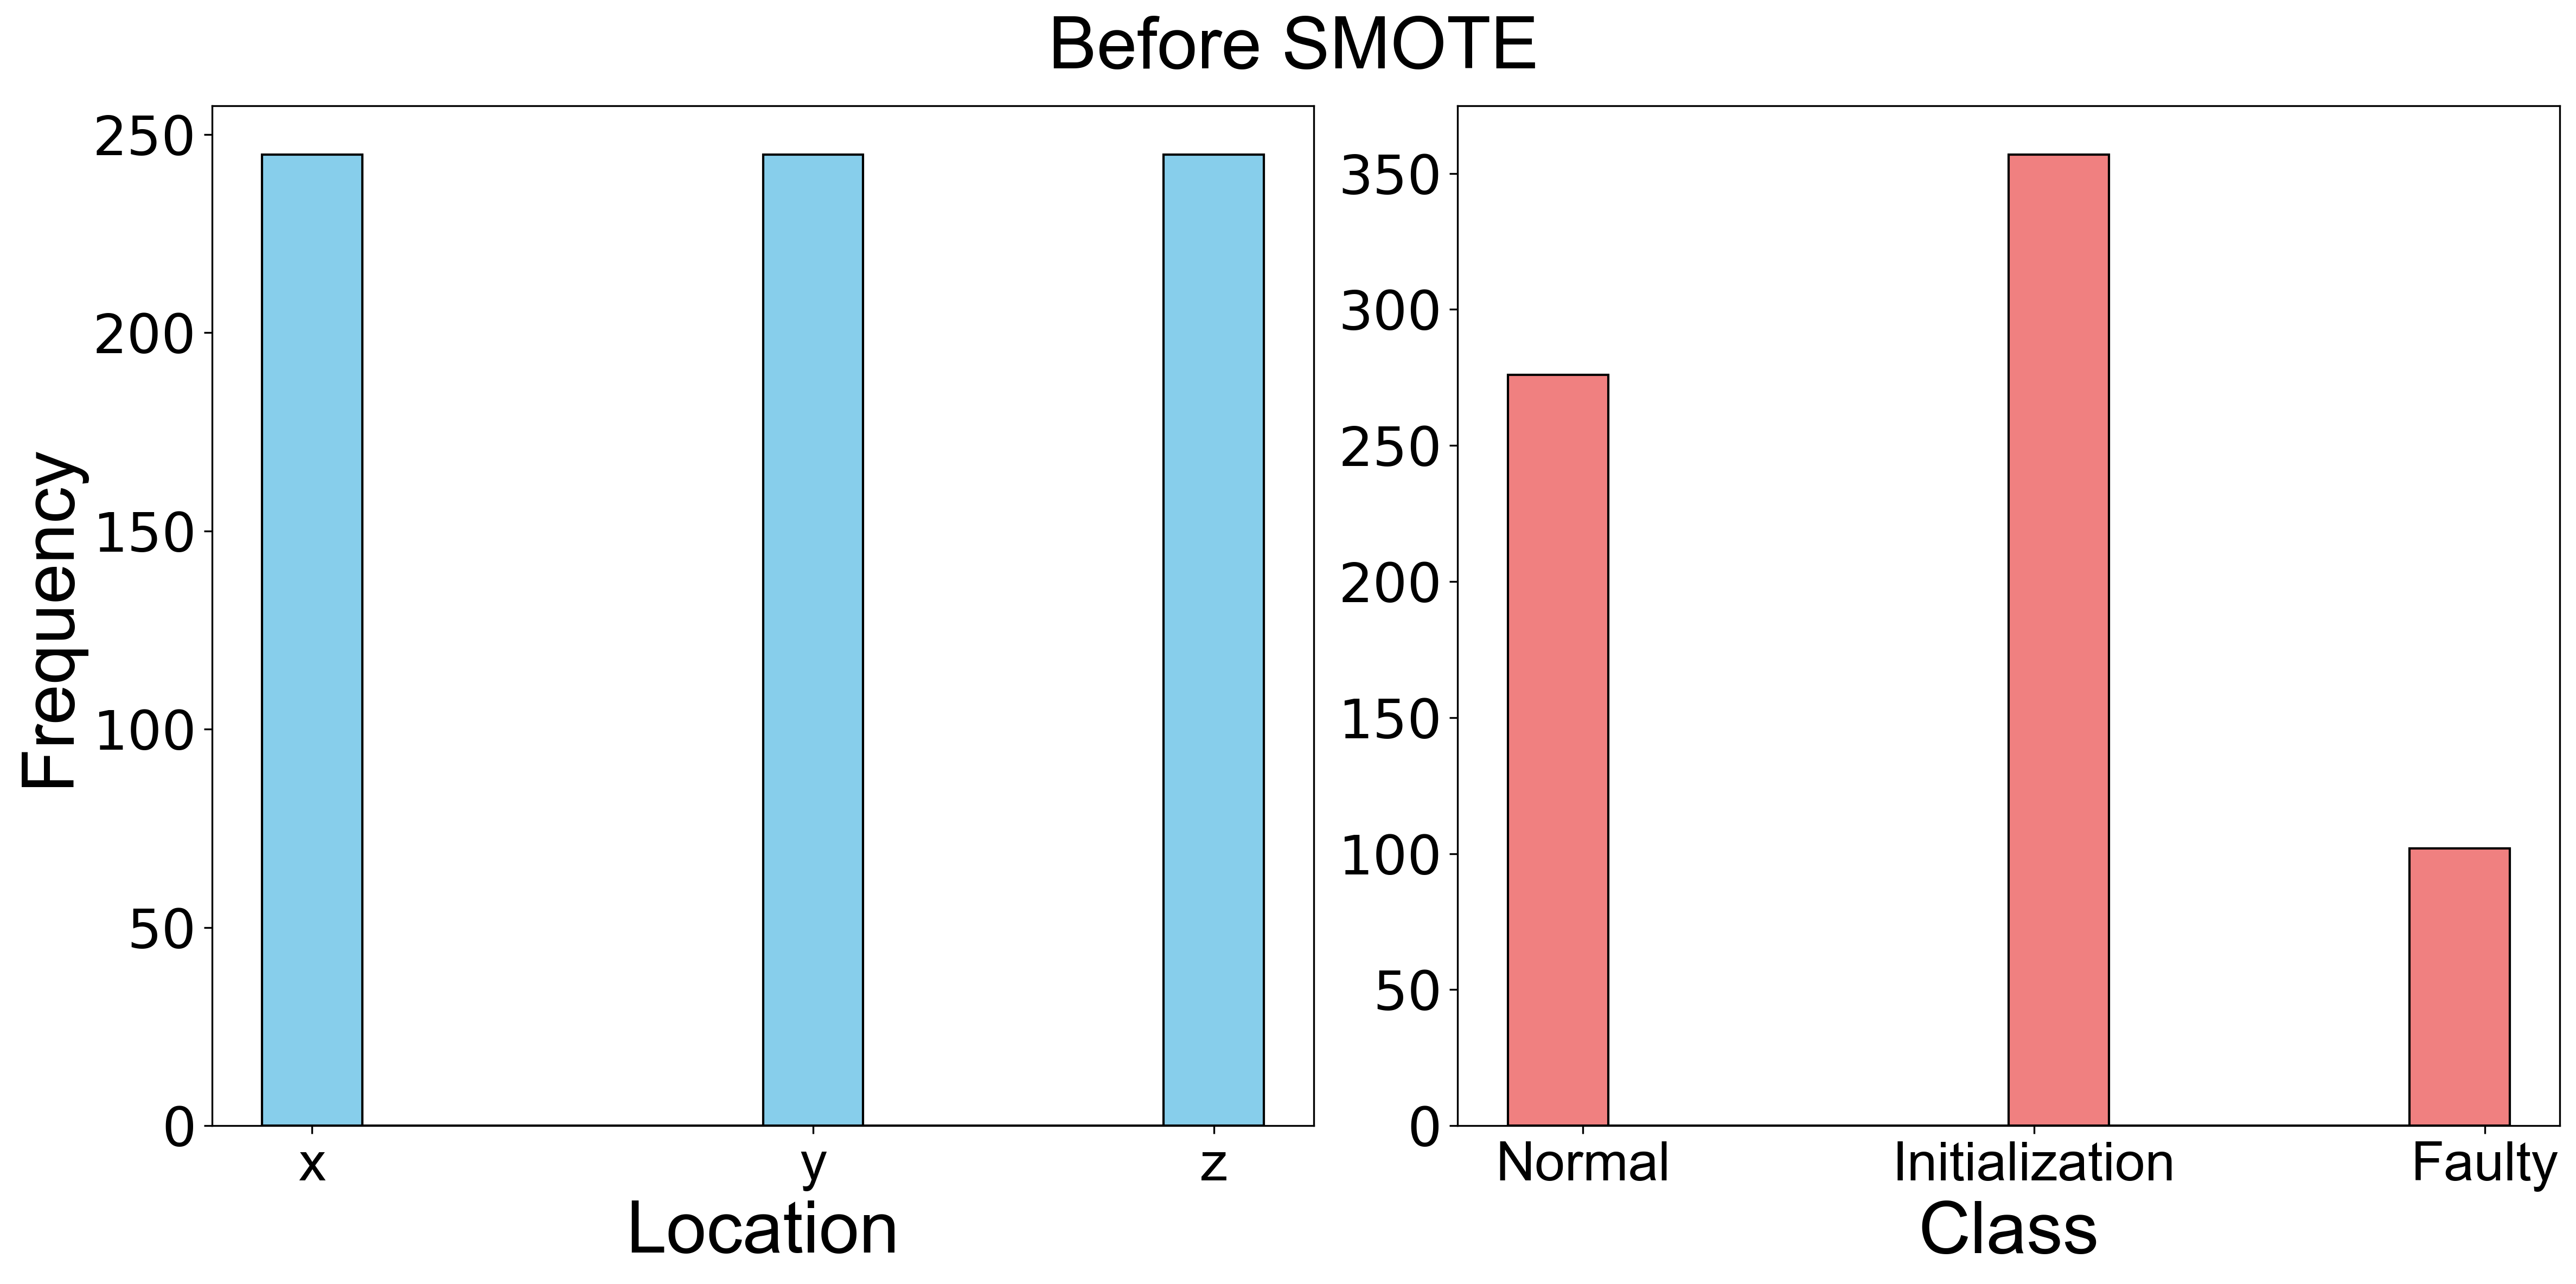

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)
plt.suptitle('Before SMOTE', fontsize=32, family='Arial')

# Plot for x (Sensor location)
axes[0].hist(x['type'], color='skyblue', edgecolor='black')
axes[0].set_xlabel('Location', fontsize=32, family='Arial')
axes[0].set_ylabel('Frequency', fontsize=32, family='Arial')
axes[0].set_xticks([0.1, 1.1, 1.9])
axes[0].set_xticklabels(['x', 'y', 'z'], fontsize=24, family='Arial')
axes[0].tick_params(axis='y', labelsize=24)

# Plot for y (Other sensor data)
axes[1].hist(y, color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Class', fontsize=32, family='Arial')
axes[1].set_xticks([0.15, 1.05, 1.95])
axes[1].set_xticklabels(['Normal', 'Initialization', 'Faulty'], fontsize=24, family='Arial')
axes[1].tick_params(axis='y', labelsize=24)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [7]:
x, y = smote.fit_resample(x, y)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=7)

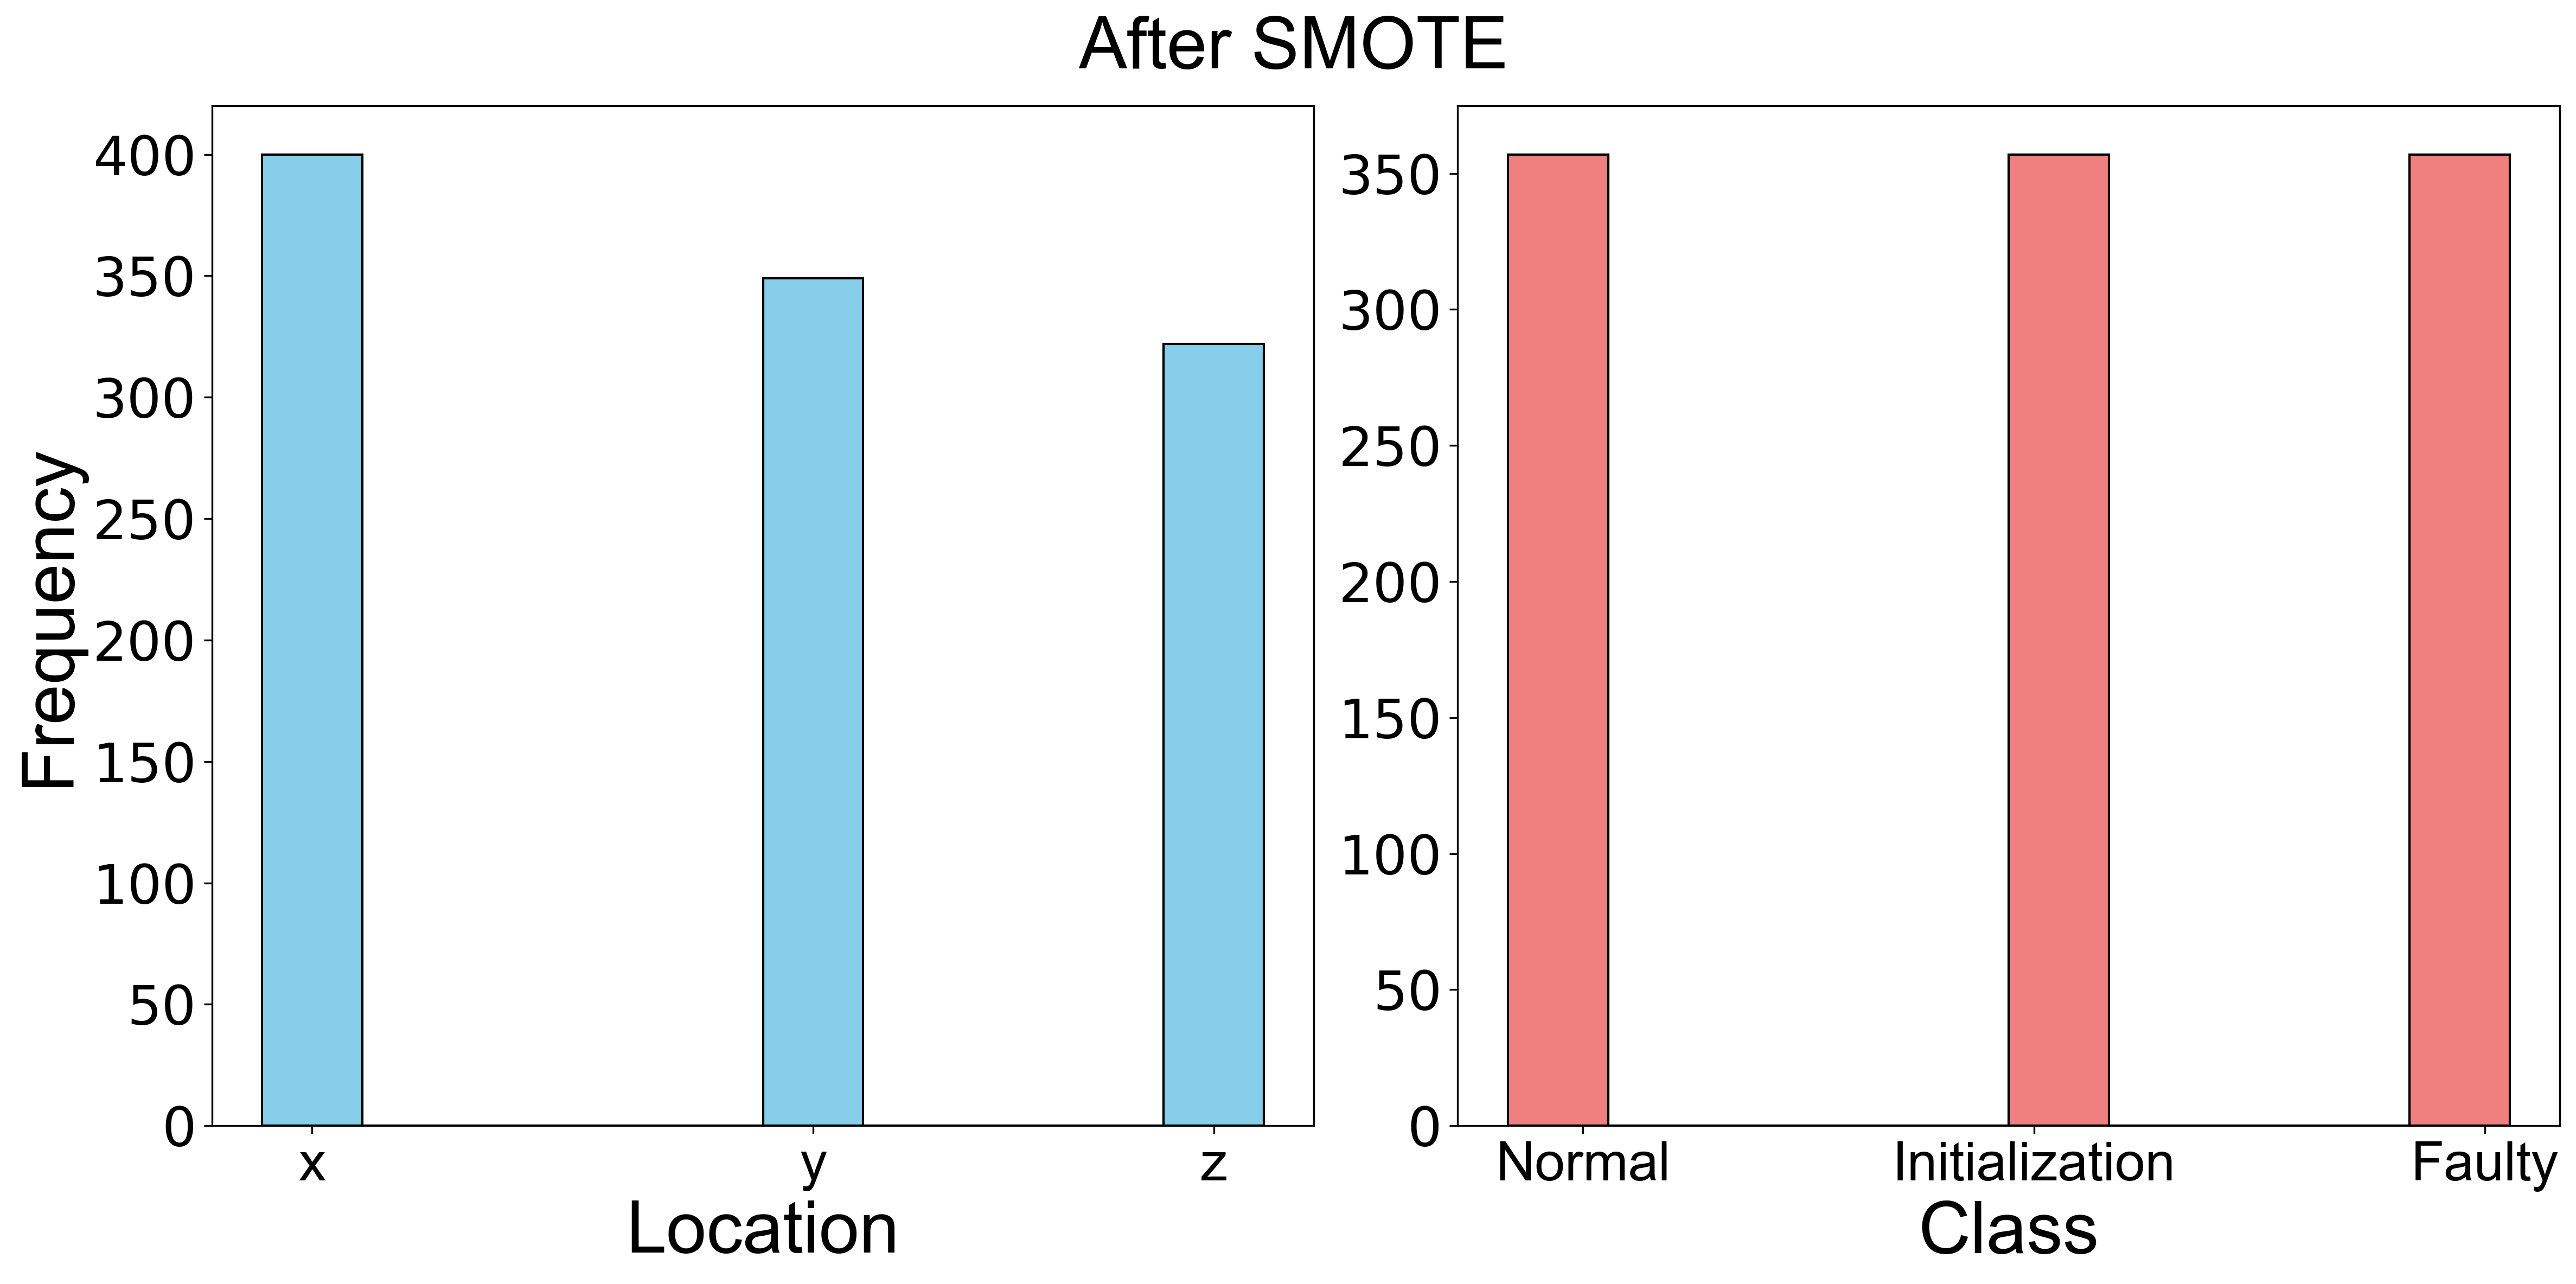

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)
plt.suptitle('After SMOTE', fontsize=32, family='Arial')

# Plot for x (Sensor location)
axes[0].hist(x['type'], color='skyblue', edgecolor='black')
axes[0].set_xlabel('Location', fontsize=32, family='Arial')
axes[0].set_ylabel('Frequency', fontsize=32, family='Arial')
axes[0].set_xticks([0.1, 1.1, 1.9])
axes[0].set_xticklabels(['x', 'y', 'z'], fontsize=24, family='Arial')
axes[0].tick_params(axis='y', labelsize=24)

# Plot for y (Other sensor data)
axes[1].hist(y, color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Class', fontsize=32, family='Arial')
axes[1].set_xticks([0.15, 1.05, 1.95])
axes[1].set_xticklabels(['Normal', 'Initialization', 'Faulty'], fontsize=24, family='Arial')
axes[1].tick_params(axis='y', labelsize=24)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

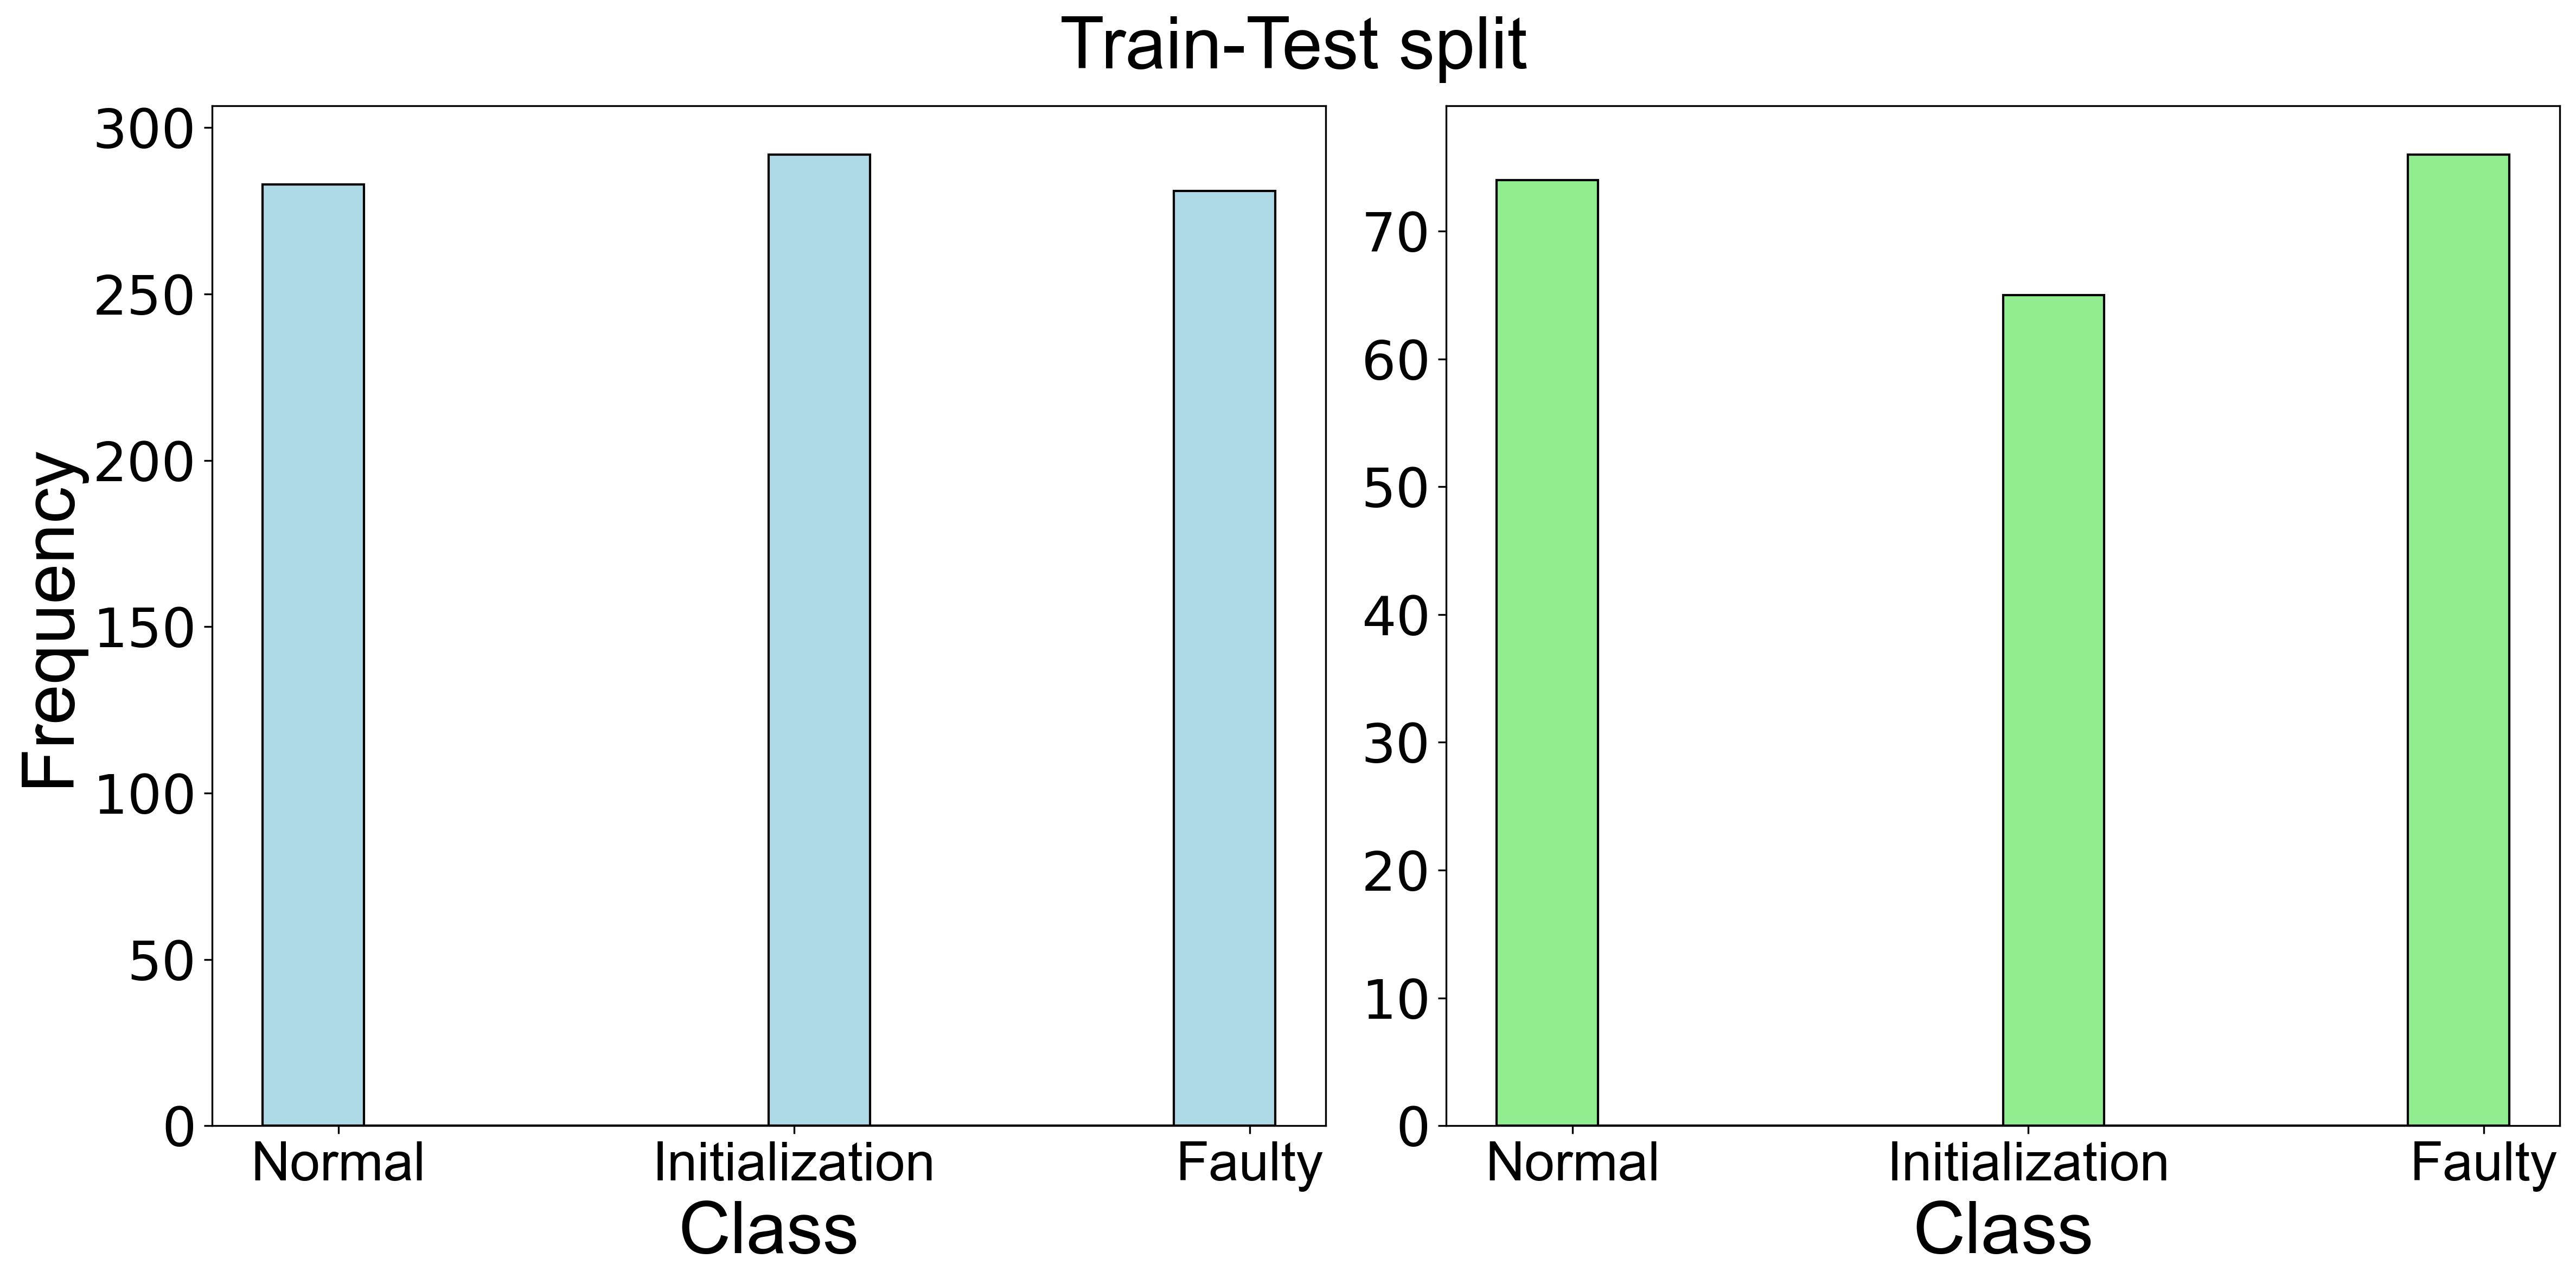

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)
plt.suptitle('Train-Test split', fontsize=32, family='Arial')

# Plot for x (Sensor location)
axes[0].hist(y_train, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Class', fontsize=32, family='Arial')
axes[0].set_ylabel('Frequency', fontsize=32, family='Arial')
axes[0].set_xticks([0.15, 1.05, 1.95])
axes[0].set_xticklabels(['Normal', 'Initialization', 'Faulty'], fontsize=24, family='Arial')
axes[0].tick_params(axis='y', labelsize=24)

# Plot for y (Other sensor data)
axes[1].hist(y_test, color='lightgreen', edgecolor='black')
axes[1].set_xlabel('Class', fontsize=32, family='Arial')
axes[1].set_xticks([0.15, 1.05, 1.95])
axes[1].set_xticklabels(['Normal', 'Initialization', 'Faulty'], fontsize=24, family='Arial')
axes[1].tick_params(axis='y', labelsize=24)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [10]:
dataset = {}
train_input=x_train.to_numpy()
train_label=y_train.to_numpy()
test_input=x_test.to_numpy()
test_label=y_test.to_numpy()

In [11]:
x_train.shape,y_train.shape,x_test.shape,y_test.shape

((856, 31), (856,), (215, 31), (215,))

In [12]:
scaler_input = MinMaxScaler()

train_input_scaled = scaler_input.fit_transform(train_input)
test_input_scaled = scaler_input.transform(test_input)

dataset['train_input'] = torch.tensor(train_input_scaled, dtype=dtype)  # Convert to the specified dtype
dataset['test_input'] = torch.tensor(test_input_scaled, dtype=dtype)    # Convert to the specified dtype

# Reshape train_label and test_label to match the expected shape (for a classification task)
dataset['train_label'] = torch.tensor(train_label[:, None], dtype=dtype)  # Ensure shape is (n_samples, 1)
dataset['test_label'] = torch.tensor(test_label[:, None], dtype=dtype)    # Ensure shape is (n_samples, 1)

In [13]:
space = {
    'grid_size': hp.quniform('grid_size', 1, 10, 1),
    'spline_order': hp.quniform('spline_order', 1, 10, 1),
    'learning_rate': hp.loguniform('learning_rate', np.log(1e-5), np.log(1e-1)),
    'lambda_l1': hp.loguniform('lambda_l1', np.log(1e-7), np.log(1e-1)),
    'lambda_l2': hp.loguniform('lambda_l2', np.log(1e-7), np.log(1e-1)),
}

In [14]:
def accuracy(predictions, labels):
    _, preds = torch.max(predictions, dim=1)
    correct = torch.sum(preds == labels).item()
    total = labels.size(0)
    return correct / total

In [17]:
param_df = pd.DataFrame(columns=['params', 'loss_curve_train','accuracy_train','accuracy_test', 'loss_curve_test', 'best_score'])
bestest_score = float('-inf')
trial_no = 0

# Initialize global variables
def objective(params):
    global trial_no, bestest_score
    trial_no += 1
    params['grid_size'] = int(params['grid_size'])
    params['spline_order'] = int(params['spline_order'])
    # Check for GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model = HybridCNNKAN(
        kan_layers=[dataset['train_input'].shape[1], 42, 3],
        grid_size=params['grid_size'],
        spline_order=params['spline_order'],
        num_classes=3
    )

    # Move the model to GPU (if available)
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'], weight_decay=params['lambda_l2'])
    num_epochs = 250
    patience = 100
    best_loss = float('-inf')
    epochs_no_improve = 0
    param_df['params'].loc[trial_no] = params
    training_loss = []
    test_loss = []
    training_acc = []
    test_acc = []

    # Move data to GPU (if available)
    train_input = dataset['train_input'].to(device)
    train_label = dataset['train_label'].to(device)
    test_input = dataset['test_input'].to(device)
    test_label = dataset['test_label'].to(device)

    for epoch in range(num_epochs):
        set_seed(42)
        model.train()
        optimizer.zero_grad()
        predictions = model(train_input)
        predictions_classes = torch.argmax(torch.softmax(predictions, dim=1), dim=1)
        main_loss = criterion(predictions, train_label.squeeze().long())
        accuracy_score_train = accuracy_score(predictions_classes.cpu().numpy(), train_label.cpu().numpy())  # .cpu() added
        loss = main_loss
        loss.backward()
        optimizer.step()
        training_loss.append(loss.item())
        training_acc.append(accuracy_score_train)
        # Evaluation
        model.eval()
        with torch.no_grad():
            val_predictions = model(test_input)
            val_loss = criterion(val_predictions, test_label.squeeze().long())
            val_accuracy = accuracy_score(torch.argmax(torch.softmax(val_predictions, dim=1), dim=1).cpu().numpy(), test_label.cpu().numpy())  # .cpu() added
            test_loss.append(val_loss.item())
            test_acc.append(val_accuracy)
            print(f"Epoch {epoch}: Train: {accuracy_score_train}, {loss.item()} ||| Test: {val_accuracy} {val_loss.item()}")

        if val_accuracy > best_loss:
            best_loss = val_accuracy
            epochs_no_improve = 0
            best_model_state = model.state_dict()
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            model.load_state_dict(best_model_state)

        # Update the bestest score
        if val_accuracy > bestest_score:
            bestest_score = val_accuracy
            torch.save({'model_state_dict': best_model_state, 'params': params}, f"bestest_model.pth")

    model.eval()
    with torch.no_grad():
        test_predictions = model(test_input)
    score = accuracy_score(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).cpu().numpy(), test_label.cpu().numpy())  # .cpu() added
    param_df.loc[trial_no] = [params, training_loss,training_acc,test_acc, test_loss, score]
    print(score)
    print(params)
    return -score

In [18]:
trials = Trials()
best_params = fmin(fn=objective,
                   space=space,
                   algo=tpe.suggest,
                   max_evals=50,
                   trials=trials)

print("Best hyperparameters:", best_params)

Epoch 0: Train: 0.3282710280373832, 1.147142984875635 ||| Test: 0.35348837209302325 1.1226607835138593
Epoch 1: Train: 0.3282710280373832, 1.1321609533208408 ||| Test: 0.35348837209302325 1.116913695669862
Epoch 2: Train: 0.3282710280373832, 1.1186048890176283 ||| Test: 0.3023255813953488 1.1160993278847964
Epoch 3: Train: 0.3411214953271028, 1.1096433309775333 ||| Test: 0.3023255813953488 1.107774708815925
Epoch 4: Train: 0.3411214953271028, 1.1010580693694214 ||| Test: 0.5023255813953489 1.096656779613574
Epoch 5: Train: 0.5490654205607477, 1.095543228588105 ||| Test: 0.34418604651162793 1.0961867029145018
Epoch 6: Train: 0.33060747663551404, 1.0989739047998635 ||| Test: 0.34418604651162793 1.0929376708582295
Epoch 7: Train: 0.33060747663551404, 1.0932518555350057 ||| Test: 0.5674418604651162 1.0835985499684282
Epoch 8: Train: 0.5852803738317757, 1.081073005164338 ||| Test: 0.3023255813953488 1.0671965794853175
Epoch 9: Train: 0.3446261682242991, 1.063882944288761 ||| Test: 0.4930232

In [19]:
param_df.to_csv(f'param_df_CNNKAN.csv')

In [20]:
checkpoint = torch.load(f"bestest_model.pth")
params1 = checkpoint['params']
model = HybridCNNKAN(
    kan_layers=[dataset['train_input'].shape[1], 42, 3],
    grid_size=params1['grid_size'],
    spline_order=params1['spline_order'],
    num_classes=3
)
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

In [21]:
model.eval()
with torch.no_grad():
    test_predictions = model(dataset['test_input'])

In [22]:
accuracy_score(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).numpy(), test_label)

0.9953488372093023

In [23]:
from sklearn.metrics import confusion_matrix


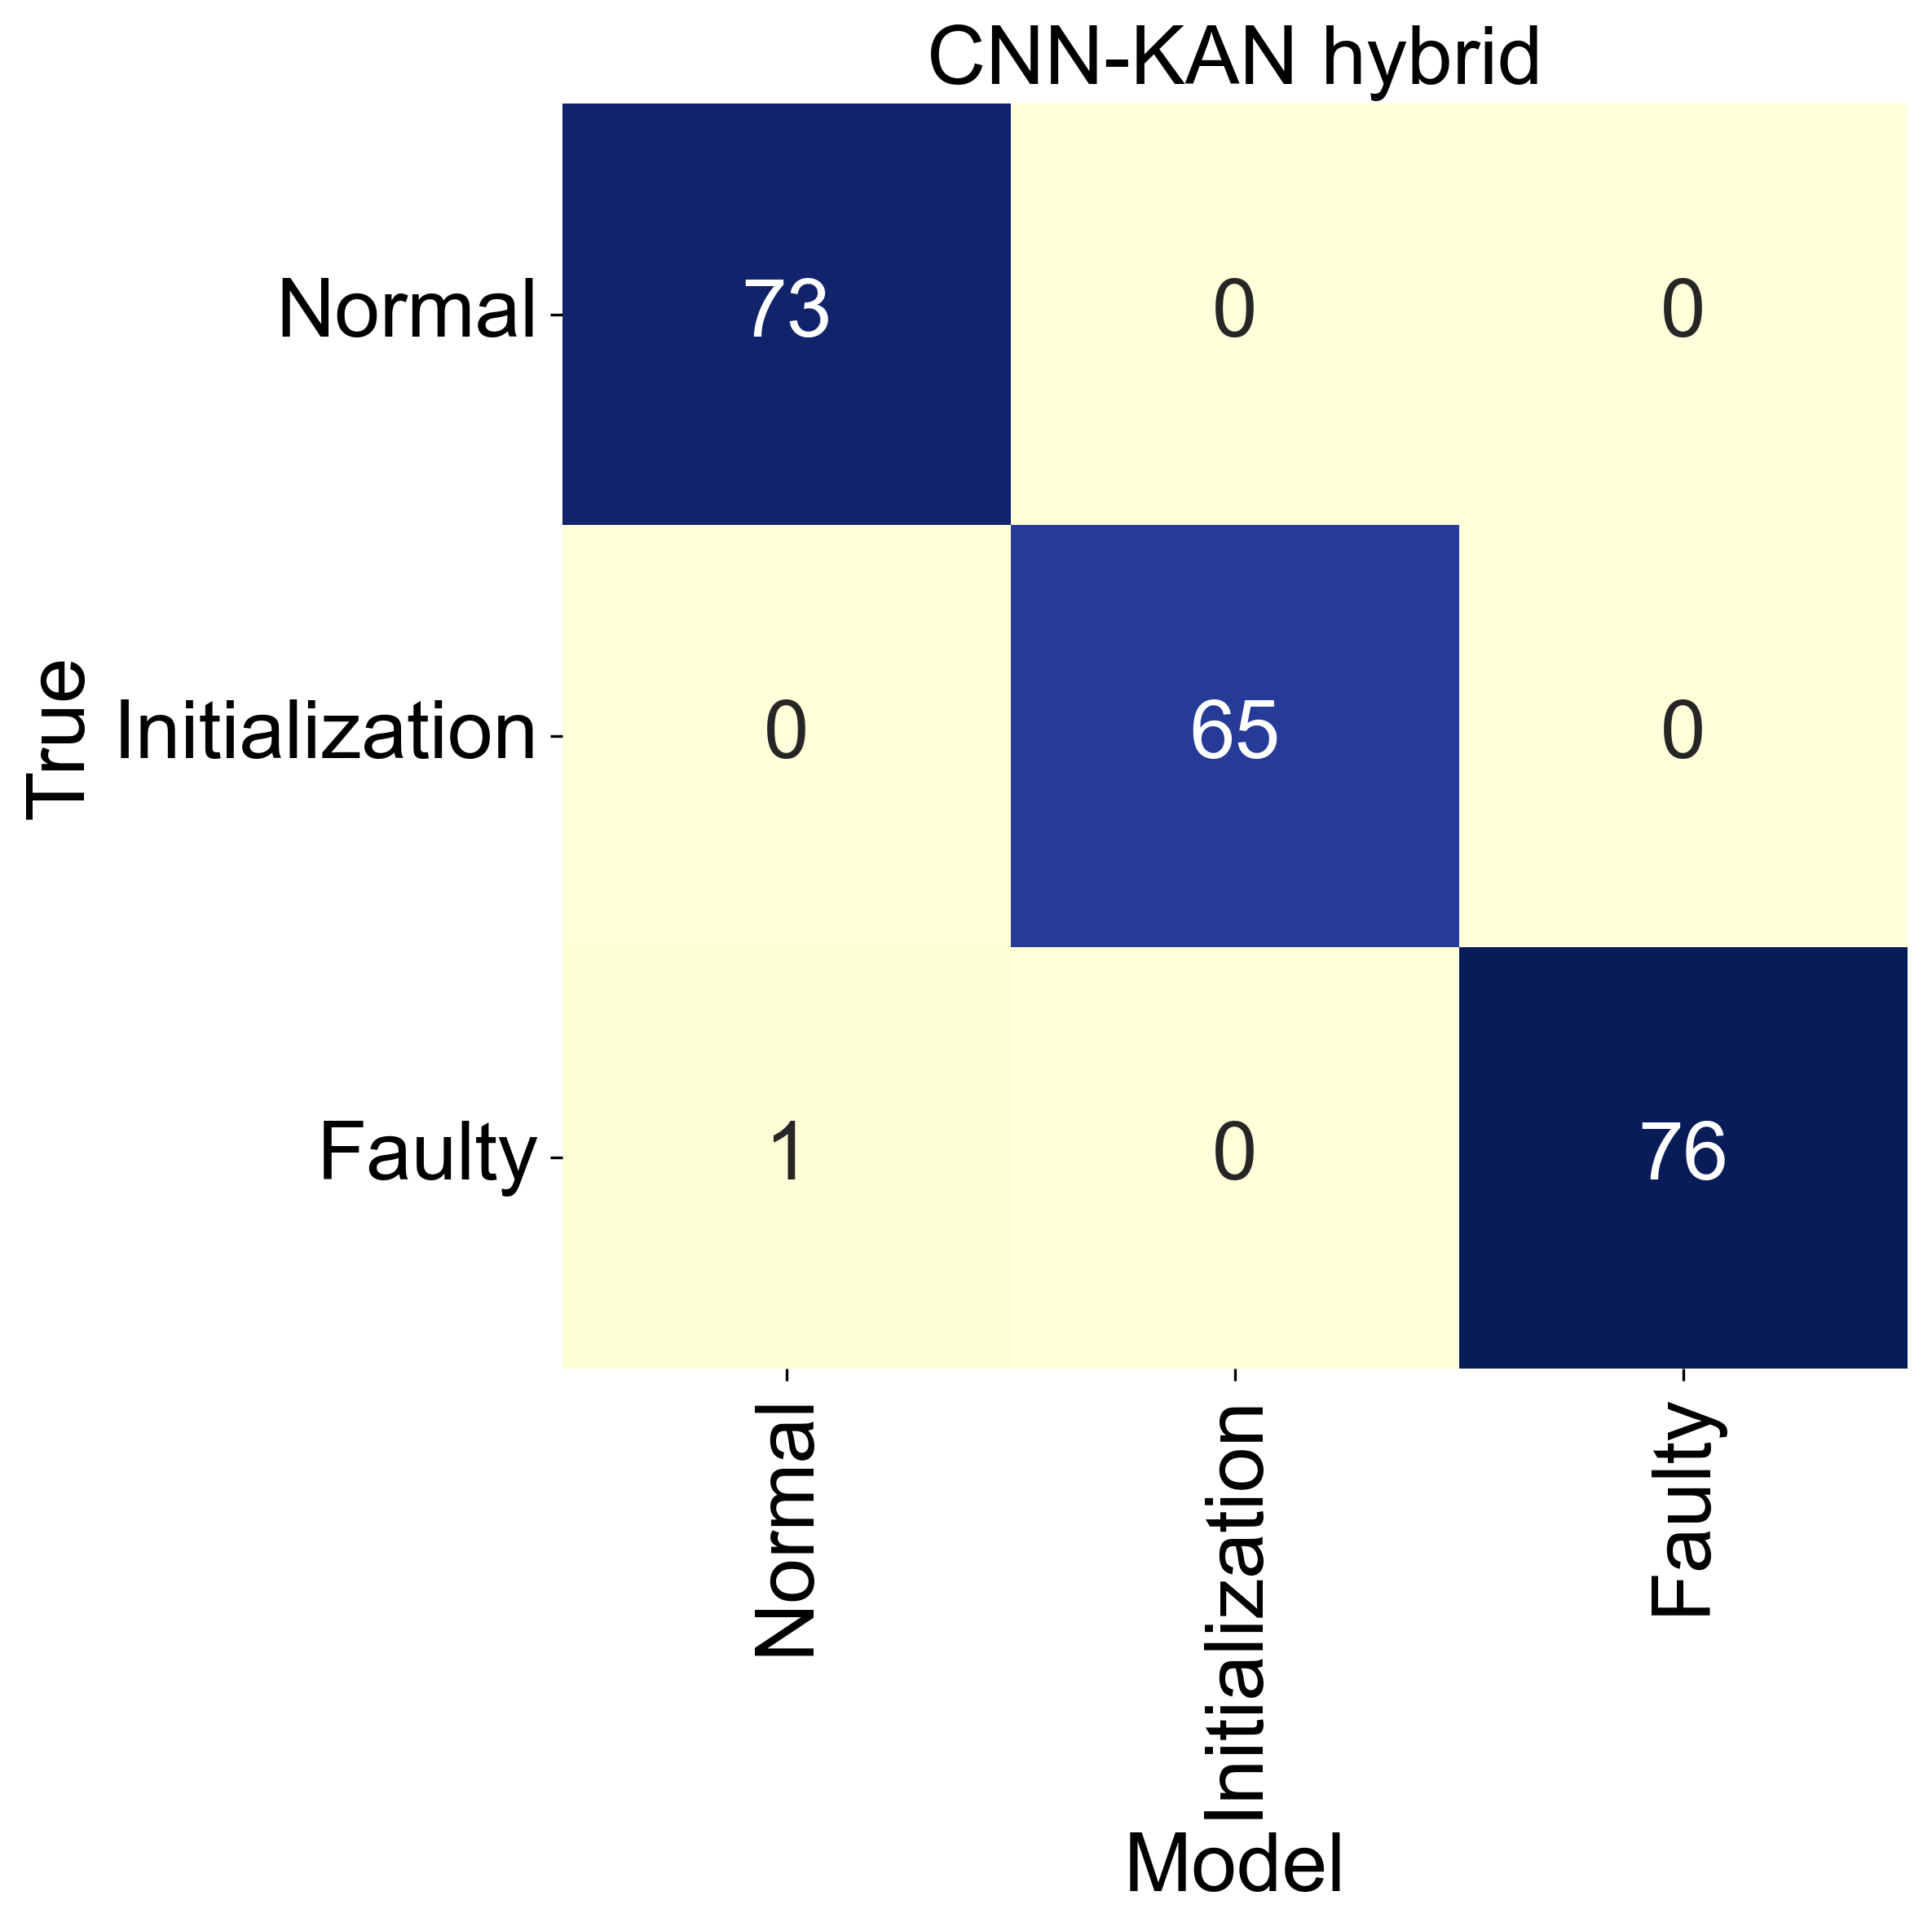

In [24]:
cm = confusion_matrix(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).numpy(), test_label)

# Plot the confusion matrix
plt.figure(figsize=(8, 8),dpi=300)
sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='g', cbar=False,
            annot_kws={"size": 24, 'fontname': 'Arial'})  # Annotation font size and font

# Adding labels and title with Arial font size 24
plt.xlabel('Model', fontsize=24, fontname='Arial')
plt.ylabel('True', fontsize=24, fontname='Arial')
plt.title('CNN-KAN hybrid', fontsize=24, fontname='Arial')
tick_labels = ['Normal', 'Initialization', 'Faulty']
# Adjust the tick labels to font size 24
plt.xticks(ticks=[0.5, 1.5, 2.5], labels=tick_labels, fontsize=24, fontname='Arial', rotation=90)
plt.yticks(ticks=[0.5, 1.5, 2.5], labels=tick_labels, fontsize=24, fontname='Arial', rotation=0)


# Display the plot
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import classification_report

print(classification_report(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).numpy(), test_label))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99        73
           1       1.00      1.00      1.00        65
           2       1.00      0.99      0.99        77

    accuracy                           1.00       215
   macro avg       1.00      1.00      1.00       215
weighted avg       1.00      1.00      1.00       215



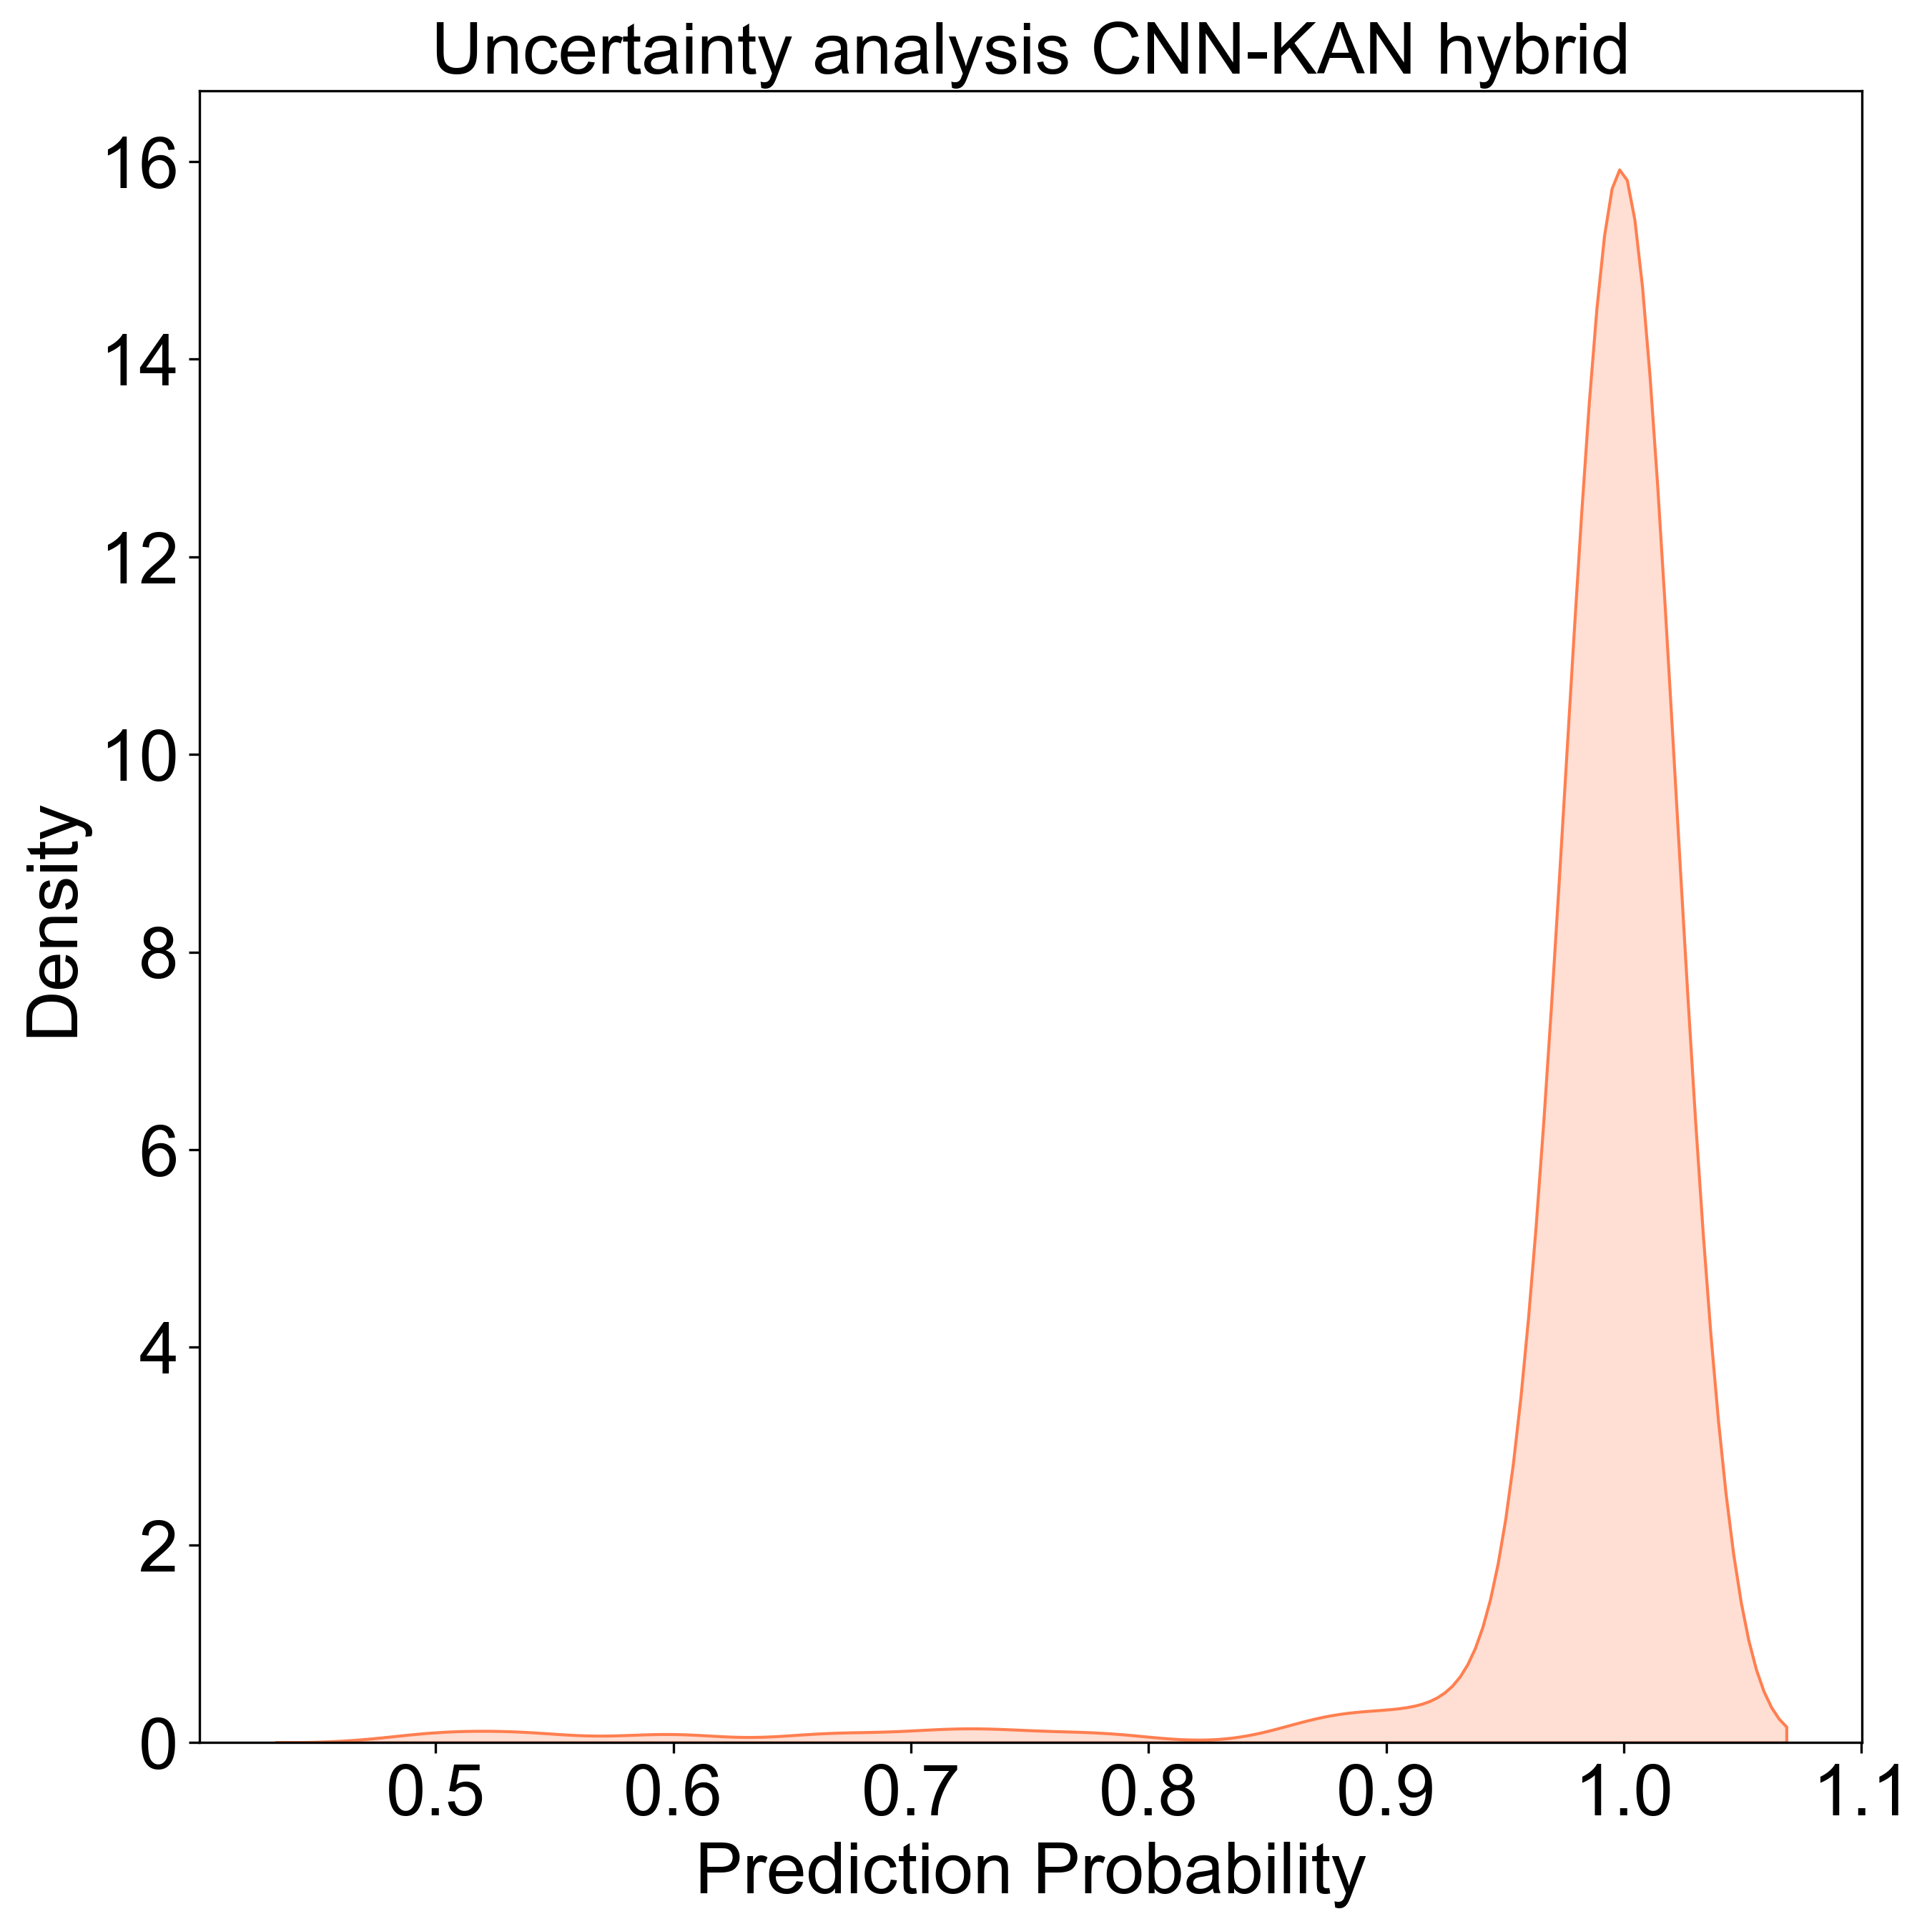

In [26]:
probabilities = np.array(torch.max(torch.softmax(test_predictions, dim=1),axis=1)[0]).tolist()
# Create KDE plot for uncertainty distribution
plt.figure(figsize=(10, 10), dpi=300)
sns.kdeplot(probabilities, color='coral', fill=True)
plt.xlabel('Prediction Probability', fontsize=24, fontname='Arial')
plt.ylabel('Density', fontsize=24, fontname='Arial')
plt.title('Uncertainty analysis CNN-KAN hybrid', fontsize=24, fontname='Arial')
plt.xticks(fontsize=24, fontname='Arial')
plt.yticks(fontsize=24, fontname='Arial')
plt.show()